In [10]:
# Setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import math

from scipy.stats import norm, binom

# Parameters

alpha = 0.95
beta = 0.05
M = 1010
lam = 0.97
theta = 0.97

# Plot settings

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

# 1

We download the daily closing prices of the S&P 500 index over the period
05/23/2016–05/22/2026.

An additional closing price from 05/20/2016 is downloaded only to compute the
first log return on 05/23/2016.

**Pseudocode**

1. Download daily S&P 500 closing prices from Yahoo Finance.
2. Keep the observations from 05/23/2016 to 05/22/2026 as the required dataset.
3. Let \(N\) be the number of observations.
4. Display the first five and last five closing prices.

In [14]:
ticker = "^GSPC"

data = yf.download(
    ticker,
    start="2016-05-20",
    end="2026-05-23",
    auto_adjust=False,
    progress=False
)

close_all = data["Close"].squeeze()

# Dataset required in the homework
prices = close_all.loc["2016-05-23":"2026-05-22"].to_frame("Close")

N = len(prices)

print("First five observations:")
display(prices.head())

print("Last five observations:")
display(prices.tail())

print("N =", N)

First five observations:


,Close
Date,
2016-05-23,2048.040039
2016-05-24,2076.060059
2016-05-25,2090.540039
2016-05-26,2090.100098
2016-05-27,2099.060059


Last five observations:


,Close
Date,
2026-05-18,7403.049805
2026-05-19,7353.609863
2026-05-20,7432.970215
2026-05-21,7445.720215
2026-05-22,7473.470215


N = 2515


In [16]:
# One log return for each date in the required dataset
log_returns = np.log(close_all / close_all.shift(1))
log_returns = log_returns.loc[prices.index]
log_returns.name = "Log Return"

print("Number of log returns =", len(log_returns))

Number of log returns = 2515



# 2

For a constant $1 position in the S&P 500, the full loss operator is

$$
L_t = -(e^{X_t}-1) = 1-e^{X_t}.
$$

For each evaluation date, the VaR is estimated from the previous $M=1010$ loss observations.

Under the empirical distribution,

$$
VaR_\alpha = L_{(\lceil M\alpha \rceil)},
$$

where the losses are arranged in increasing order.

An exceedance occurs when

$$
L_t > VaR_t.
$$

**Pseudocode**

1. Set $\alpha=0.95$ and $M=1010$.
2. Convert each log return into a full loss: $L_t=1-e^{X_t}$.
3. For each observation $i=M,\ldots,N-1$:
   - Take the previous $M$ losses.
   - Sort them in increasing order.
   - Set $k=\lceil M\alpha \rceil$.
   - Set the VaR equal to the $k$-th ordered loss.
   - Compare the realized loss with the VaR.
   - Record an exceedance if the realized loss is larger than the VaR.
4. Store the VaR estimates, realized losses, and exceedance indicators.


In [21]:
alpha = 0.95
beta = 0.05
M = 1010

losses = 1 - np.exp(log_returns)


def empirical_var(sample, alpha):
    ordered = np.sort(sample)
    k = math.ceil(alpha * len(ordered))
    return ordered[k - 1]

In [23]:
var_emp = []
loss_emp = []
exceed_emp = []
dates = []

for i in range(M, N):
    
    # Previous M losses only
    window = losses.iloc[i-M:i]
    
    # VaR estimated at the beginning of the evaluation period
    var_i = empirical_var(window, alpha)
    
    # Realized loss
    loss_i = losses.iloc[i]
    
    # Exceedance
    exceed_i = loss_i > var_i
    
    dates.append(losses.index[i])
    var_emp.append(var_i)
    loss_emp.append(loss_i)
    exceed_emp.append(exceed_i)

In [25]:
results_emp = pd.DataFrame({
    "Loss": loss_emp,
    "VaR": var_emp,
    "Exceedance": exceed_emp
}, index=dates)

results_emp.index.name = "Date"

J = len(results_emp)

print("J =", J)
print("N - M =", N - M)

display(results_emp.head())

J = 1505
N - M = 1505


,Loss,VaR,Exceedance
Date,,,
2020-05-28,0.002108,0.017327,False
2020-05-29,-0.004812,0.017327,False
2020-06-01,-0.003751,0.017327,False
2020-06-02,-0.008211,0.017327,False
2020-06-03,-0.013649,0.017327,False


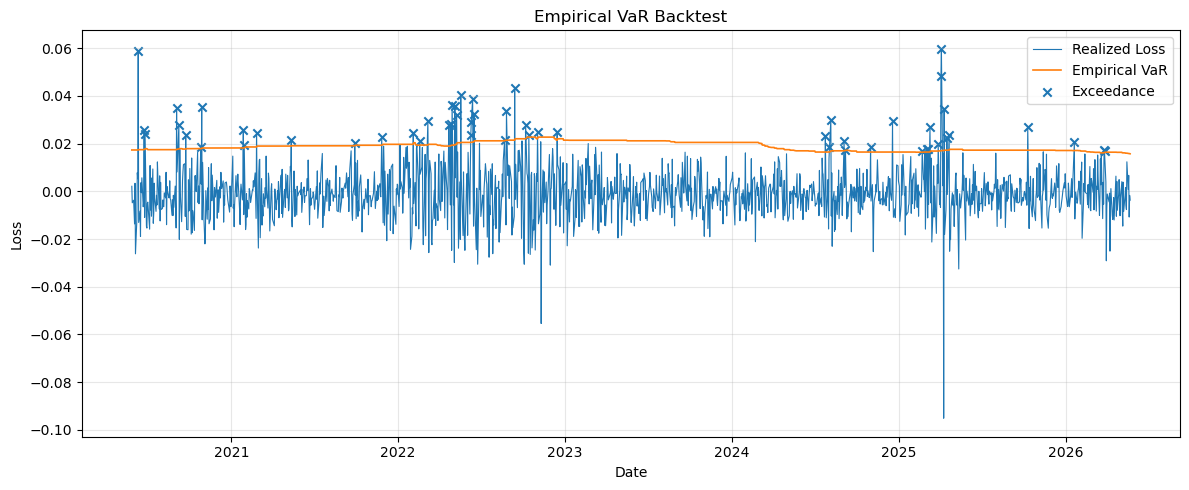

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    results_emp.index,
    results_emp["Loss"],
    label="Realized Loss",
    linewidth=0.8
)

plt.plot(
    results_emp.index,
    results_emp["VaR"],
    label="Empirical VaR",
    linewidth=1.2
)

exceedances = results_emp[results_emp["Exceedance"]]

plt.scatter(
    exceedances.index,
    exceedances["Loss"],
    marker="x",
    label="Exceedance"
)

plt.xlabel("Date")
plt.ylabel("Loss")
plt.title("Empirical VaR Backtest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [29]:
K_emp = results_emp["Exceedance"].sum()

print("Empirical exceedances =", K_emp)
print("Exceedance rate =", K_emp / J)

Empirical exceedances = 55
Exceedance rate = 0.036544850498338874



# 3

We assume that the log returns are conditionally normally distributed:

$$
X_t \sim N(\mu_t,\sigma_t^2).
$$

The EWMA estimates are updated according to

$$
\mu_{t+1} = \lambda\mu_t + (1-\lambda)X_t,
$$

$$
\sigma_{t+1}^2 = \theta\sigma_t^2 + (1-\theta)(X_t-\mu_t)^2,
$$

with $\lambda=\theta=0.97$.

The initial mean and variance are estimated from the first $M=1010$ log returns.

For the full loss operator, the VaR is

$$
VaR_t = 1-\exp\left(\mu_t+\sigma_t\Phi^{-1}(1-\alpha)\right).
$$



**Pseudocode**

1. Set $\lambda=\theta=0.97$.
2. Estimate the initial mean and variance from the first $M=1010$ log returns.
3. For each evaluation period:
   - Compute the VaR using the current EWMA mean and variance.
   - Observe the realized full loss.
   - Record an exceedance if the realized loss exceeds the VaR.
   - Update the EWMA variance using the current return and previous mean.
   - Update the EWMA mean using the current return.
4. Repeat over the same $J=N-M$ evaluation periods used in Task 2.


In [32]:
lam = 0.97
theta = 0.97

# Initial estimates from first M log returns
mu = log_returns.iloc[:M].mean()
variance = log_returns.iloc[:M].var(ddof=1)

print("Initial mu =", mu)
print("Initial variance =", variance)
print("Initial sigma =", np.sqrt(variance))

Initial mu = 0.0003877353917233607
Initial variance = 0.00015407389529538027
Initial sigma = 0.012412650615214313


In [36]:
var_ewma = []
loss_ewma = []
exceed_ewma = []
mu_series = []
sigma_series = []
dates = []

z = norm.ppf(1 - alpha)

for i in range(M, N):
    
    sigma = np.sqrt(variance)
    
    # VaR forecast before observing return i
    var_i = 1 - np.exp(mu + sigma * z)
    
    # Realized return and loss
    x_i = log_returns.iloc[i]
    loss_i = 1 - np.exp(x_i)
    
    # Exceedance
    exceed_i = loss_i > var_i
    
    dates.append(log_returns.index[i])
    var_ewma.append(var_i)
    loss_ewma.append(loss_i)
    exceed_ewma.append(exceed_i)
    mu_series.append(mu)
    sigma_series.append(sigma)
    
    # EWMA update
    mu_old = mu
    
    variance = (
        theta * variance
        + (1 - theta) * (x_i - mu_old)**2
    )
    
    mu = (
        lam * mu_old
        + (1 - lam) * x_i
    )

In [38]:
results_ewma = pd.DataFrame({
    "Loss": loss_ewma,
    "VaR": var_ewma,
    "Mu": mu_series,
    "Sigma": sigma_series,
    "Exceedance": exceed_ewma
}, index=dates)

results_ewma.index.name = "Date"

display(results_ewma.head())

,Loss,VaR,Mu,Sigma,Exceedance
Date,,,,,
2020-05-28,0.002108,0.019830,0.000388,0.012413,False
2020-05-29,-0.004812,0.019613,0.000313,0.012233,False
2020-06-01,-0.003751,0.019223,0.000447,0.012073,False
2020-06-02,-0.008211,0.018854,0.000546,0.011904,False
2020-06-03,-0.013649,0.018459,0.000775,0.011798,False


In [40]:
assert len(results_ewma) == J
assert results_ewma.index.equals(results_emp.index)

In [42]:
K_ewma = results_ewma["Exceedance"].sum()

print("EWMA exceedances =", K_ewma)
print("Exceedance rate =", K_ewma / J)

EWMA exceedances = 94
Exceedance rate = 0.06245847176079734


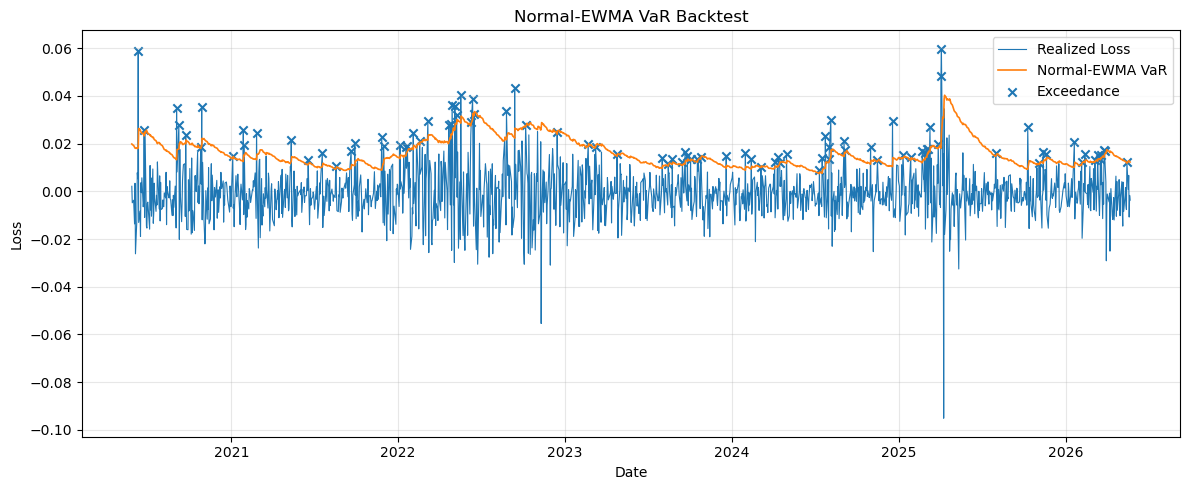

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(
    results_ewma.index,
    results_ewma["Loss"],
    label="Realized Loss",
    linewidth=0.8
)

plt.plot(
    results_ewma.index,
    results_ewma["VaR"],
    label="Normal-EWMA VaR",
    linewidth=1.2
)

exceedances_ewma = results_ewma[results_ewma["Exceedance"]]

plt.scatter(
    exceedances_ewma.index,
    exceedances_ewma["Loss"],
    marker="x",
    label="Exceedance"
)

plt.xlabel("Date")
plt.ylabel("Loss")
plt.title("Normal-EWMA VaR Backtest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

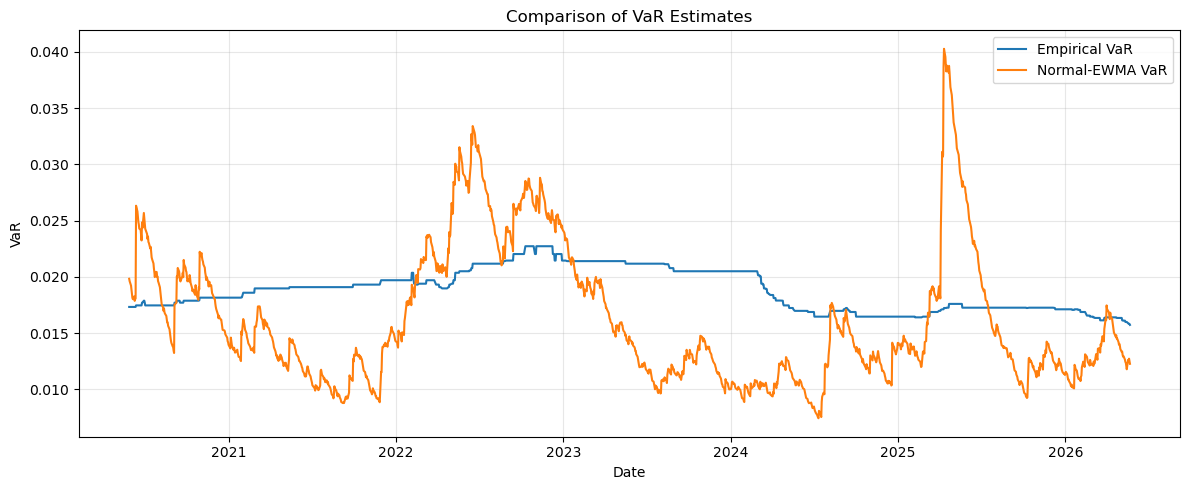

In [46]:
plt.figure(figsize=(12, 5))

plt.plot(
    results_emp.index,
    results_emp["VaR"],
    label="Empirical VaR"
)

plt.plot(
    results_ewma.index,
    results_ewma["VaR"],
    label="Normal-EWMA VaR"
)

plt.xlabel("Date")
plt.ylabel("VaR")
plt.title("Comparison of VaR Estimates")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


# 4

Under a correctly calibrated VaR model at confidence level $\alpha=0.95$, the theoretical probability of an exceedance is

$$
p = 1-\alpha = 0.05.
$$

Over $J=N-M$ evaluation periods, the number of exceedances follows a binomial distribution under the null hypothesis of independent exceedances:

$$
K \sim \mathrm{Binomial}(J,0.05).
$$

The expected number of exceedances is

$$
E[K] = J(1-\alpha).
$$

We construct a $1-\beta=95\%$ confidence interval using the binomial quantiles:

$$
[L,U] =
\left[
F_K^{-1}\left(\frac{\beta}{2}\right),
F_K^{-1}\left(1-\frac{\beta}{2}\right)
\right].
$$

We compare the observed number of exceedances for each model with this interval.



**Pseudocode**

1. Set $\alpha=0.95$ and $\beta=0.05$.
2. Compute the theoretical exceedance probability $p=1-\alpha$.
3. Set the number of evaluation periods to $J=N-M$.
4. Assume $K\sim\mathrm{Binomial}(J,p)$ under the null hypothesis.
5. Compute the confidence interval:
   - Lower bound: $L=F_K^{-1}(\beta/2)$.
   - Upper bound: $U=F_K^{-1}(1-\beta/2)$.
6. Count the observed exceedances for the empirical and normal-EWMA methods.
7. Check whether each observed count belongs to $[L,U]$.
8. Reject the null hypothesis for any model whose exceedance count falls outside the interval.


In [49]:
p = 1 - alpha

lower = int(binom.ppf(beta / 2, J, p))
upper = int(binom.ppf(1 - beta / 2, J, p))

expected = J * p

print("J =", J)
print("Expected exceedances =", expected)
print(f"95% confidence interval = [{lower}, {upper}]")

J = 1505
Expected exceedances = 75.25000000000007
95% confidence interval = [59, 92]


In [51]:
K_emp = int(results_emp["Exceedance"].sum())
K_ewma = int(results_ewma["Exceedance"].sum())

emp_inside = lower <= K_emp <= upper
ewma_inside = lower <= K_ewma <= upper

print("\nEmpirical method")
print("Observed exceedances =", K_emp)
print("Inside confidence interval =", emp_inside)

print("\nNormal-EWMA method")
print("Observed exceedances =", K_ewma)
print("Inside confidence interval =", ewma_inside)


Empirical method
Observed exceedances = 55
Inside confidence interval = False

Normal-EWMA method
Observed exceedances = 94
Inside confidence interval = False


In [53]:
summary = pd.DataFrame({
    "Method": ["Empirical", "Normal-EWMA"],
    "Exceedances": [K_emp, K_ewma],
    "Exceedance Rate": [K_emp / J, K_ewma / J],
    "Inside 95% CI": [emp_inside, ewma_inside]
})

display(summary)

,Method,Exceedances,Exceedance Rate,Inside 95% CI
0,Empirical,55,0.036545,False
1,Normal-EWMA,94,0.062458,False



**Conclusion**

Over $J=1505$ evaluation periods, the expected number of exceedances is $75.25$, with a 95% confidence interval of $[59,92]$.

The empirical method produces **55 exceedances (3.65%)**, below the confidence interval, suggesting that it overestimates risk. Its four-year rolling window may adjust slowly to changing market conditions.

The Normal-EWMA method produces **94 exceedances (6.25%)**, above the confidence interval, suggesting that it underestimates tail risk, potentially because of the normality assumption.

Therefore, **both models fail the 5% binomial backtest**, although in opposite directions. The empirical method appears overly conservative, while the Normal-EWMA method is insufficiently conservative.
